# Feature engineering

Feature engineering là tạo thêm cột đầu vào từ dữ liệu có sẵn để model đoán tốt hơn. Bài dùng bài toán dự đoán số đơn hàng mỗi giờ của các cửa hàng: từ thời điểm đặt hàng tạo ra giờ trong ngày, ngày trong tuần, số đơn của giờ trước. Quy tắc quan trọng nhất là chỉ dùng thông tin đã có tại lúc dự đoán. Nếu lỡ dùng số đơn của chính giờ cần dự đoán, điểm validation sẽ rất đẹp nhưng model không dùng được thật.

> **Mục tiêu**
>
> - Tạo đặc trưng từ cột số, cột phân loại, thời gian và lịch sử.
> - Dùng lag, rolling và encoding theo nhóm.
> - So các nhóm đặc trưng bằng cùng fold; tránh leakage.

## Mỗi mô hình cần một kiểu đặc trưng

Ví dụ đơn giản nhất của tạo đặc trưng là tính tuổi từ ngày sinh. Học máy cổ điển cần người làm việc này; mạng học sâu ở các chương sau tự học đặc trưng từ ảnh, chữ, âm thanh. Với dữ liệu bảng cỡ vừa, gradient boosting trên cây kèm vài đặc trưng tốt thường là lựa chọn mạnh nhất.

Cùng một dữ liệu, cách biến đổi đúng phụ thuộc mô hình sẽ dùng:

| Thao tác | Mô hình tuyến tính, kNN, SVM | Mô hình cây |
|---|---|---|
| Chuẩn hóa thang đo | Cần | Không cần |
| Log cho biến lệch | Thường có ích | Gần như không đổi, vì log giữ thứ tự |
| One-hot cột phân loại | Cần | Thường kém ordinal hoặc hỗ trợ danh mục sẵn có |
| Tương tác, tỉ số | Phải tự tạo | Học được phần nào, nhưng tạo sẵn vẫn giúp |
| Giá trị thiếu | Phải điền | XGBoost, LightGBM, HistGB tự xử lý |

**Hỏi nhanh.** Áp $\log(1 + x)$ cho cột thu nhập, rồi học lại một cây quyết định trên cùng dữ liệu. Chuyện gì xảy ra?

- A. Cây sâu hơn, vì phân phối cân đối hơn
- B. Cây chia train y hệt, chỉ có ngưỡng là đổi
- C. Cây tốt hơn hẳn, nhờ bớt lệch phải
- D. Phải chuẩn hóa lại thì cây mới chạy được

<details><summary>Đáp án</summary>

B. Cây chia train y hệt, chỉ có ngưỡng là đổi

Log là hàm đồng biến nên giữ nguyên thứ tự. Mỗi phép chia “$x \le a$” ứng đúng với một phép chia “$\log(1+x) \le \log(1+a)$”. Khác biệt nhỏ chỉ nằm ở ngưỡng đặt giữa hai giá trị liên tiếp, nên một điểm mới rơi đúng vào khe ấy có thể bị xếp khác.

</details>

## Đặc trưng số

- **Biến đổi.** Biến lệch phải (thu nhập, số lượt xem) qua $\log(1 + x)$ trở nên cân đối hơn, có ích cho mô hình tuyến tính và kNN. Với target lệch như giá nhà, học $\log(\text{giá})$ biến sai số thành sai số theo tỉ lệ: lệch 10% ở căn 3 tỉ hay căn 300 tỉ tính như nhau, nên vài căn rất đắt không lấn át loss.
- **Tỉ số và hiệu.** Tổng tiền chia số món ra giá trung bình mỗi món; số đơn trừ số đơn hủy ra số đơn thành công. Những phép tính con người thấy “có nghĩa” thường là đặc trưng tốt, vì cây phải dùng rất nhiều ngưỡng mới xấp xỉ được một phép chia số học. Điều kiện duy nhất: mọi thành phần của phép tính phải có sẵn lúc dự đoán.
- **Rời rạc hóa** (binning) thành khoảng, ví dụ nhóm tuổi: đôi khi giúp mô hình tuyến tính bắt được quan hệ không đơn điệu.



**Hỏi nhanh.** Cần dự đoán giá nhà trước khi bán. Cột `price/area` được tạo từ giá bán thực tế. Lúc dự đoán, `area` đã biết nhưng `price` thì chưa. Feature này có hợp lệ không?

- A. Có, vì chia cho diện tích đã loại ảnh hưởng của target
- B. Có, nếu chỉ fit scaler trên train
- C. Có, nếu dùng cây thay cho linear regression
- D. Không, vì phép tính cần chính target chưa biết

<details><summary>Đáp án</summary>

D. Không, vì phép tính cần chính target chưa biết

Một phép biến đổi của target thì vẫn chứa target. Scaler hay việc chọn mô hình nào cũng không tạo ra được thông tin có sẵn trước khi bán.

</details>

## Đặc trưng phân loại

| Cách mã hóa | Ý tưởng | Dùng khi |
|---|---|---|
| One-hot | Mỗi giá trị một cột 0/1 | Ít giá trị khác nhau; mô hình tuyến tính |
| Ordinal | Mỗi giá trị một số nguyên | Có thứ tự thật (S < M < L), hoặc cho mô hình cây |
| Tần suất | Thay giá trị bằng số lần xuất hiện | Nhiều giá trị; độ phổ biến có ý nghĩa |
| Target encoding | Thay giá trị bằng trung bình $y$ của nó | Rất nhiều giá trị (mã quận, mã sản phẩm) |

Target encoding mạnh nhưng nguy hiểm: dùng $y$ để tạo đặc trưng chính là cửa ngõ rò rỉ dữ liệu. Hai quy tắc:

1. **Tính out-of-fold.** Giá trị mã hóa của một mẫu chỉ được tính từ các fold khác, không bao giờ dùng chính $y$ của nó.
2. **Làm mượt** (smoothing) cho giá trị hiếm. Với giá trị $c$ xuất hiện $n_c$ lần, trung bình nhãn $\bar y_c$, trung bình toàn cục $\bar y$ và hệ số $m$:

$$\text{TE}(c) = \frac{n_c\,\bar y_c + m\,\bar y}{n_c + m}.$$

Ví dụ: quận A chỉ có 3 mẫu và cả 3 đều có nhãn 1, trong khi tỉ lệ chung là 0.3. Với $m = 10$, $\text{TE}(A) = (3 \cdot 1 + 10 \cdot 0.3)/13 \approx 0.46$, không phải 1.0. Ba mẫu chưa đủ để tin rằng quận A “chắc chắn” mang nhãn 1.



**Hỏi nhanh.** Vẫn $m = 10$ và tỉ lệ chung là $0.3$. Quận B có 20 mẫu, một nửa mang nhãn 1. Giá trị mã hóa của B bằng bao nhiêu?

- A. khoảng $0.43$
- B. $0.50$
- C. $0.30$
- D. khoảng $0.40$

<details><summary>Đáp án</summary>

A. khoảng $0.43$

$(20 \cdot 0.5 + 10 \cdot 0.3)/30 = 13/30 \approx 0.43$. Có 20 mẫu thì trung bình riêng của B được tin nhiều hơn quận A chỉ có ba mẫu, nhưng vẫn bị kéo một phần về $0.3$.

</details>

CatBoost cài sẵn một biến thể an toàn của target encoding; LightGBM cũng nhận trực tiếp cột phân loại.

Khi một mẫu có thể mang nhiều giá trị cùng lúc, như một phim có nhiều diễn viên trong danh sách 200 người, dùng multi-hot: 200 cột 0/1, cho phép nhiều số 1 trên cùng một hàng.

## Giá trị thiếu

Trước khi xử lý, hỏi vì sao ô bị trống. Xóa mọi dòng có ô trống thường đắt hơn tưởng: 20 cột, mỗi ô thiếu ngẫu nhiên 15% thì chỉ $0.85^{20} \approx 4\%$ số dòng còn đủ.

- Điền bằng median (số) hoặc giá trị phổ biến nhất (phân loại), học trên train rồi áp lên mọi tập.
- Thêm cột chỉ báo “có bị thiếu không”. **Việc thiếu cũng là thông tin**: khách bỏ trống ô thu nhập có thể khác hẳn khách điền đầy đủ.
- Với các thư viện boosting, thường để nguyên NaN cho mô hình tự học hướng đi tốt nhất.

Điền trung bình còn làm cột trông ít biến động hơn thực tế: cột 2, 4, 8 cùng hai ô trống điền bằng trung bình $14/3$ thì phương sai giảm từ $6.22$ xuống $3.73$.

**Hỏi nhanh.** Khách bỏ trống ô thu nhập có tỉ lệ vỡ nợ 40%, khách điền đầy đủ chỉ 10%. Ta điền median vào ô trống và không thêm cột nào khác. Hệ quả chính là gì?

- A. Mô hình mất đi tín hiệu “bỏ trống”, một tín hiệu rất mạnh
- B. Không sao, vì median giữ nguyên phân phối
- C. Tốt hơn, vì dữ liệu không còn giá trị NaN
- D. Mô hình báo lỗi, vì cột đã đổi kiểu dữ liệu

<details><summary>Đáp án</summary>

A. Mô hình mất đi tín hiệu “bỏ trống”, một tín hiệu rất mạnh

Sau khi điền, khách bỏ trống trông y hệt khách có thu nhập trung vị. Thêm một cột đánh dấu ô thiếu thì giữ lại được khác biệt 40% so với 10%. Điền median còn làm phân phối dồn thêm một đỉnh ở giữa.

</details>

## Thời gian

- Trước hết đưa mọi cách viết ngày (“11/10/2026”, “2026-10-11”) về một định dạng, và biết chắc “11/10” là ngày–tháng hay tháng–ngày.
- Tách ngày giờ thành năm, tháng, ngày trong tuần, giờ, ngày lễ, cuối tuần.
- Đặc trưng có chu kỳ như giờ trong ngày nên mã hóa trên đường tròn, để 23 giờ và 0 giờ nằm gần nhau:

$$x_{\sin} = \sin\frac{2\pi t}{T}, \qquad x_{\cos} = \cos\frac{2\pi t}{T}, \qquad T = 24.$$

Với cách này, khoảng cách giữa 23 giờ và 0 giờ là $0.26$, còn giữa 12 giờ và 0 giờ là $2$, đúng như trực giác. Nếu chỉ dùng số giờ thì 23 và 0 cách nhau xa nhất.



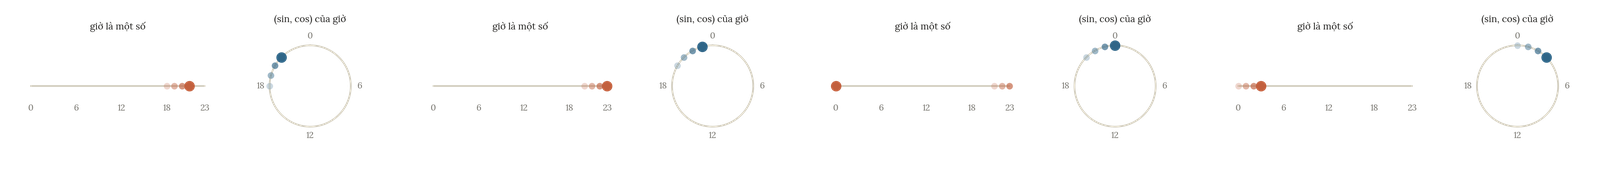

**Hỏi nhanh.** Sau khi mã hóa giờ bằng sin và cos với $T = 24$, khoảng cách Euclid giữa 22 giờ và 2 giờ bằng bao nhiêu?

- A. $20$
- B. $1$
- C. $4$
- D. khoảng $0.26$

<details><summary>Đáp án</summary>

B. $1$

Hai mốc cách nhau 4 giờ, tức $60^\circ$ trên đường tròn bán kính 1, nên dây cung dài $2\sin 30^\circ = 1$. Dùng số giờ thô thì ra 20, coi hai mốc rất gần nhau là rất xa nhau.

</details>

## Chuỗi thời gian

Dự đoán $y_t$ từ quá khứ, các đặc trưng hay dùng:

- **Lag**: $y_{t-1}, y_{t-7}, y_{t-365}$, tùy chu kỳ của dữ liệu.
- **Thống kê cửa sổ trượt** (rolling): trung bình, độ lệch chuẩn của $k$ bước gần nhất.
- **Sai phân quá khứ**: $y_{t-1} - y_{t-2}$ để dự đoán $y_t$, đo xu hướng từ những giá trị đã có.

Quy tắc vàng: mọi đặc trưng tại thời điểm $t$ chỉ được dùng thông tin **trước** $t$. Rolling mean phải dịch lùi một bước (`shift(1)`) trước khi lấy cửa sổ; nếu không, giá trị cần dự đoán đã nằm sẵn trong đặc trưng. Validation cũng phải chia theo thời gian (bài 1.3).

**Hỏi nhanh.** Dùng sai phân $y_t - y_{t-1}$ làm feature để dự đoán $y_t$. Có hợp lệ không?

- A. Có, vì sai phân đo xu hướng gần nhất
- B. Có, nếu $y_{t-1}$ đã được lấy bằng `shift(1)`
- C. Không, vì nó chứa chính $y_t$
- D. Không, vì sai phân chỉ thêm nhiễu

<details><summary>Đáp án</summary>

C. Không, vì nó chứa chính $y_t$

Biết $y_t - y_{t-1}$ và biết $y_{t-1}$ là biết luôn $y_t$. Sai phân hợp lệ phải lùi lại một bước: $y_{t-1} - y_{t-2}$.

</details>

## Lag và rolling bằng pandas

Cửa hàng A có doanh số 5, 7, 6 ở ba giờ liên tiếp. Khi dự đoán giờ kế tiếp, `lag_1` bằng 6 và trung bình hai giá trị gần nhất là $(7+6)/2=6.5$. Nhưng nếu đang dự đoán chính giờ có số 6 mà rolling lại gồm số 6, ta đã dùng đáp án. `shift(1)` đẩy mỗi giá trị xuống một hàng: doanh số của một giờ chỉ được dùng từ giờ sau.

In [ ]:
import numpy as np
import pandas as pd

history = pd.DataFrame({"shop": ["A", "A", "A", "B", "B"],
                        "time": [1, 2, 3, 1, 2],
                        "sales": [5., 7., 6., 3., 4.]})
history = history.sort_values(["shop", "time"])
history["lag_1"] = history.groupby("shop")["sales"].shift(1)
history["mean_prev_2"] = history.groupby("shop")["sales"].transform(
    lambda s: s.shift(1).rolling(2, min_periods=2).mean()
)
print(history.to_string(index=False))
assert history.loc[2, "mean_prev_2"] == 6.

shop  time  sales  lag_1  mean_prev_2
   A     1    5.0    NaN          NaN
   A     2    7.0    5.0          NaN
   A     3    6.0    7.0          6.0
   B     1    3.0    NaN          NaN
   B     2    4.0    3.0          NaN


Ở giờ 3 của A, `mean_prev_2` là 6 vì hai giờ trước có 5 và 7. Đầu chuỗi thiếu lịch sử nên NaN là đúng, không phải code hỏng. Có thể điền bằng giá trị học trên train, hoặc để model tự xử lý NaN; điền bằng dữ liệu tương lai cho “đỡ mất hàng” là leakage. Nhớ sort theo thời gian trong từng nhóm trước khi shift.



**Hỏi nhanh.** Quên `shift(1)`, viết thẳng `rolling(2).mean()` trên doanh số 5, 7, 6 của cửa hàng A. Giá trị ở giờ 3 bằng bao nhiêu?

- A. $6$, giống hệt bản có shift
- B. $7$, giá trị gần nhất trước đó
- C. $6.5$, có chứa luôn target của giờ 3
- D. NaN, vì chưa đủ lịch sử

<details><summary>Đáp án</summary>

C. $6.5$, có chứa luôn target của giờ 3

$(7 + 6)/2 = 6.5$, trong đó 6 chính là doanh số cần dự đoán. Validation sẽ đẹp, còn lúc dùng thật thì cột này không tính được.

</details>

**Dự báo nhiều giờ một lúc.** Nếu phải dự đoán cả khối giờ tương lai một lần, doanh số của những giờ đầu khối **chưa có** để làm lag cho giờ sau. Khi đó hoặc dự đoán đệ quy (lấy dự đoán của giờ trước làm lag), hoặc chỉ dùng lag đủ xa, ví dụ đoán 24 giờ tới thì chỉ dùng lag từ 24 trở lên. Không được lấy target thật của validation làm lag như thể đã biết.

## Đặc trưng gộp nhóm

Thống kê theo nhóm thường là đặc trưng mạnh nhất trong dữ liệu bảng: số đơn trung bình của mỗi khách, giá trung bình của mỗi danh mục, độ lệch của một giao dịch so với thói quen của chính người đó. Với `pandas`, đó là một dòng `groupby(...).transform("mean")`. Nếu thống kê có dùng $y$, quy tắc out-of-fold ở phần target encoding vẫn áp dụng.

**Hỏi nhanh.** Thêm cột `shop_mean = groupby("shop")["sales"].transform("mean")`, tính trên toàn bảng train theo giờ, rồi dùng nó để dự đoán `sales`. Có vấn đề gì?

- A. Không sao, đây chỉ là thống kê theo nhóm
- B. Cột này trùng thông tin với one-hot của shop
- C. `transform` làm xáo trộn thứ tự các hàng
- D. Mỗi hàng chứa cả sales của chính nó lẫn sales tương lai

<details><summary>Đáp án</summary>

D. Mỗi hàng chứa cả sales của chính nó lẫn sales tương lai

Phép trung bình ấy gồm cả giờ đang dự đoán và mọi giờ sau nó. Cách hợp lệ khi có thời gian là lấy trung bình mở rộng đã dịch đi một bước: `s.shift(1).expanding().mean()`.

</details>

## Giá trị mới ở test

Mã cửa hàng là danh mục, không phải số để so lớn nhỏ. One-hot dành một cột cho mỗi giá trị đã thấy; ở test có mã mới thì `handle_unknown="ignore"` cho toàn số 0 trong nhóm cột đó. Code chạy được, nhưng mô hình không biết gì về cửa hàng mới. Muốn đoán tốt cửa hàng mới, cần đặc trưng chung như khu vực hay diện tích, nếu thông tin đó có sẵn.

Code dưới ghép điền thiếu, chuẩn hóa và one-hot vào một `ColumnTransformer`, fit trên train rồi transform một cửa hàng mới.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

train_features = pd.DataFrame({"size": [10., np.nan, 30.], "shop": ["A", "B", "A"]})
new_features = pd.DataFrame({"size": [20.], "shop": ["C"]})
numeric = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
preprocessor = ColumnTransformer([
    ("number", numeric, ["size"]),
    ("category", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["shop"]),
])
encoded_train = preprocessor.fit_transform(train_features)
encoded_new = preprocessor.transform(new_features)
print("shape:", encoded_train.shape, encoded_new.shape)
print("mẫu mới:", encoded_new.round(3).tolist())

shape: (3, 3) (1, 3)
mẫu mới: [[0.0, 0.0, 0.0]]


Hàng mới có cột số chuẩn hóa bằng 0 vì 20 bằng median/mean của train sau điền thiếu, còn hai cột A/B đều bằng 0 vì C chưa xuất hiện. Quan trọng là không `fit_transform` lại trên từng tập: như vậy số cột và ý nghĩa cột có thể đổi, chưa kể thống kê validation bị dùng để học phép biến đổi.

**Hỏi nhanh.** Trong code trên, nếu lỡ gọi `preprocessor.fit_transform(new_features)` thay vì `transform`, đầu ra có shape gì?

- A. `(1, 3)`, như cũ
- B. `(1, 4)`
- C. `(1, 2)`
- D. Báo lỗi, vì C chưa từng xuất hiện

<details><summary>Đáp án</summary>

C. `(1, 2)`

Fit lại thì encoder chỉ thấy C, nên phần one-hot còn một cột, cộng thêm cột `size` là hai. Mô hình đã học trên ba cột sẽ báo lỗi. Tệ hơn, nếu số cột tình cờ khớp, nó sẽ đọc nhầm ý nghĩa của các cột.

</details>

## Văn bản, ảnh, âm thanh

Dữ liệu không có cấu trúc cũng cần thành vector:

- Văn bản: đếm từ, TF-IDF (bài 6.1), hoặc embedding câu (bài 6.2).
- Ảnh, âm thanh: embedding từ model pretrained (Chương 4).

Sau đó, mọi kỹ thuật của chương này dùng lại được: PCA cho embedding, kNN trên embedding, gradient boosting trên embedding ghép với đặc trưng bảng.

## Làm có kiểm chứng

Thêm đặc trưng là thêm giả thuyết; giả thuyết cần được kiểm. Quy trình đơn giản mà hiệu quả:

1. Dựng baseline và ghi điểm cross-validation.
2. Thêm **một nhóm** đặc trưng, đo lại bằng đúng cùng các fold. Giữ nếu tăng rõ, bỏ nếu không.
3. Ghi lại mọi thử nghiệm: nhóm đặc trưng, điểm từng fold, thời gian chạy.

Làm ngược lại, tức bỏ từng nhóm khỏi mô hình đầy đủ (ablation), cho biết nhóm nào thật sự gánh điểm. Feature importance của mô hình cây chỉ là gợi ý; permutation importance trên validation đáng tin hơn.

Đừng lọc đặc trưng chỉ bằng điểm của từng cột riêng lẻ: với $y = x_1 \text{ XOR } x_2$, mỗi cột một mình không nói gì về $y$ (thông tin tương hỗ bằng 0), nhưng hai cột cùng nhau xác định $y$ hoàn toàn.

**Hỏi nhanh.** Mô hình đầy đủ có MAE 2.0 trên các fold cố định. Bỏ nhóm lag thì MAE là 2.9, bỏ nhóm thời gian là 2.02, bỏ nhóm thống kê cửa hàng là 2.3. Nhóm nào đóng góp nhiều nhất?

- A. Nhóm lag
- B. Nhóm thời gian
- C. Nhóm thống kê cửa hàng
- D. Chưa biết khi chưa xem feature importance

<details><summary>Đáp án</summary>

A. Nhóm lag

Bỏ nhóm lag làm MAE tăng 0.9, nhiều nhất. Nhóm thời gian chỉ đổi 0.02, có thể chỉ là dao động giữa các lần chạy. Bỏ từng nhóm rồi đo trên cùng các fold trả lời trực tiếp hơn feature importance.

</details>

Mỗi đặc trưng nên trả lời được hai câu: nó được biết lúc nào, và vì sao có thể liên quan target. Ví dụ “giờ cuối tuần” có thể đổi nhu cầu thật; còn “mã đơn” có thể chỉ vô tình tăng theo thời gian.

**Hỏi nhanh.** Với mô hình cây, cột `order_id` đứng đầu bảng feature importance. Phản ứng hợp lý nhất là gì?

- A. Giữ lại, vì importance cao là feature tốt
- B. Nghi ngờ, vì mã có thể tăng dần theo thời gian
- C. Chuẩn hóa `order_id` rồi học lại
- D. One-hot `order_id` cho mô hình hiểu rõ hơn

<details><summary>Đáp án</summary>

B. Nghi ngờ, vì mã có thể tăng dần theo thời gian

Mã tăng dần đang lén mã hóa thời gian. Với cách chia ngẫu nhiên, nó cho mô hình biết mẫu nằm ở giai đoạn nào. Đến test ở tương lai, mã lại nằm ngoài khoảng đã thấy trong train. Hãy kiểm bằng cách chia theo thời gian, hoặc bỏ cột ấy rồi so trên cùng các fold.

</details>

## Danh sách kiểm tra rò rỉ

Trước khi vui mừng vì điểm validation tăng vọt, tự hỏi:

- Đặc trưng này có dùng $y$ của chính mẫu đó không?
- Có dùng thông tin từ tương lai không?
- Có được tính trên cả train lẫn test cùng lúc, kiểu chuẩn hóa hay đếm tần suất trên toàn bộ dữ liệu, theo cách mà lúc triển khai thật không làm được không?
- Lúc dự đoán thật, đặc trưng này có sẵn không?

Một đặc trưng tốt đến mức khó tin thì thường đúng là không nên tin.

**Hỏi nhanh.** Đếm tần suất của mã sản phẩm trên train và test gộp lại, không dùng nhãn. Cách này hợp lệ khi nào?

- A. Luôn hợp lệ, vì không đụng tới nhãn
- B. Không bao giờ, vì đã nhìn vào dữ liệu test
- C. Chỉ khi mô hình phía sau là cây
- D. Khi lúc dự đoán thật cũng có sẵn cả lô ấy

<details><summary>Đáp án</summary>

D. Khi lúc dự đoán thật cũng có sẵn cả lô ấy

Câu hỏi là thông tin có sẵn lúc dự đoán hay không, chứ không chỉ là có dùng $y$ hay không. Nếu đề cho cả tập test cùng lúc, đếm trên cả lô là hợp lệ. Nếu phải dự đoán từng đơn khi nó đến thì không.

</details>

## Dùng thư viện

In [ ]:
import numpy as np
import pandas as pd

df = pd.DataFrame({
    "time": pd.date_range("2026-10-01", periods=6, freq="h"),
    "shop": ["A", "B", "A", "A", "B", "A"],
    "sales": [5, 3, 7, 6, 4, 9],
})
df["hour_sin"] = np.sin(2 * np.pi * df["time"].dt.hour / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["time"].dt.hour / 24)
df["lag_1"] = df.groupby("shop")["sales"].shift(1)
df["roll_mean_2"] = df.groupby("shop")["sales"].transform(lambda s: s.shift(1).rolling(2).mean())
df["shop_count"] = df.groupby("shop").cumcount()  # số lần đã xuất hiện trước hàng hiện tại
print(df.drop(columns="time").round(2).to_string())

  shop  sales  hour_sin  hour_cos  lag_1  roll_mean_2  shop_count
0    A      5      0.00      1.00    NaN          NaN           0
1    B      3      0.26      0.97    NaN          NaN           0
2    A      7      0.50      0.87    5.0          NaN           1
3    A      6      0.71      0.71    7.0          6.0           2
4    B      4      0.87      0.50    3.0          NaN           1
5    A      9      0.97      0.26    6.0          6.5           3


**Hỏi nhanh.** Hàng 4, thuộc cửa hàng B, có `lag_1 = 3` nhưng `roll_mean_2` lại là NaN. Vì sao?

- A. `shift` làm mất dữ liệu của B
- B. Trước đó B mới có một giờ bán
- C. Rolling tính chung cả A và B
- D. Do `round(2)` khi in kết quả

<details><summary>Đáp án</summary>

B. Trước đó B mới có một giờ bán

Trong nhóm B, trước hàng 4 chỉ có một giờ bán với doanh số 3. Cửa sổ hai giá trị chưa đầy nên NaN là đúng. Nếu rolling tính chung cả hai cửa hàng thì đã ra một con số.

</details>

## Khi đi thi

- Với mỗi cột, hỏi: sinh ra lúc nào, lúc dự đoán đã có chưa.
- Target encoding và mọi thống kê dùng nhãn phải tính out-of-fold.
- Mỗi lần thêm một nhóm feature, so trên cùng các fold.

## Tóm tắt

- Đặc trưng là nơi kiến thức về bài toán biến thành điểm số; cách biến đổi phụ thuộc mô hình.
- Cột phân loại: one-hot, ordinal, tần suất, target encoding (out-of-fold, có làm mượt).
- Thời gian: tách thành phần, mã hóa chu kỳ bằng sin/cos; chuỗi thời gian dùng lag và rolling chỉ từ quá khứ.
- Thêm đặc trưng có kiểm chứng bằng cross-validation; luôn soát rò rỉ.

## Kiểm tra cuối bài

Mười câu kiểm cả cách hiểu, phép tính và quy trình. Câu sai chỉ ra phần cần đọc lại; hãy làm trước khi mở lời giải.

**Câu 1.** Cần dự đoán giá bán của ngày mai. Nếu các dữ kiện được mô tả đúng, feature nào tạo được ngay lúc dự đoán?

- A. Giá bán thực tế ngày mai chia cho diện tích
- B. Chênh lệch giữa giá dự đoán và giá bán thực tế ngày mai
- C. Nhóm giá chia theo target của chính ngôi nhà
- D. Giá của các nhà lân cận đã bán tháng trước

<details><summary>Đáp án</summary>

D. Giá của các nhà lân cận đã bán tháng trước

Dữ liệu đã quan sát được trước thời điểm dự đoán thì dùng được. Ba feature còn lại đều cần target tương lai của chính mẫu.

</details>
**Câu 2.** Dự đoán số khách của một buổi hòa nhạc. Một feature là “số khách của buổi trước, nếu biết”. Nên mã hóa thế nào?

- A. One-hot cho từng giá trị số khách
- B. Giữ dạng số đã chuẩn hóa, điền 0 khi không biết
- C. Giữ dạng số đã chuẩn hóa, thêm một cột đánh dấu khi không biết
- D. Bỏ cột này, vì đôi khi bị thiếu

<details><summary>Đáp án</summary>

C. Giữ dạng số đã chuẩn hóa, thêm một cột đánh dấu khi không biết

Số khách có thứ tự và độ lớn, nên giữ ở dạng số. Điền 0 khiến “không biết” trông như “buổi trước vắng tanh”. Cột đánh dấu giúp mô hình phân biệt hai tình huống ấy. Cũng trong đề này, thể loại nhạc (classical, folk, rock, pop, rap) thì nên one-hot, vì không có thứ tự.
Phỏng theo: [MIT 6.036 · Final, Spring 2022 · Q5(a)](https://introml.mit.edu/_static/fall22/final/review/6036_final_sp22.pdf#page=12)

</details>
**Câu 3.** Doanh số các giờ đã biết là 4, 8, 6. Ta dự báo giờ kế tiếp, dùng trung bình trượt của hai giờ gần nhất. Feature hợp lệ bằng bao nhiêu?

- A. 7
- B. 6
- C. 8
- D. (6 + doanh số của giờ cần dự báo)/2

<details><summary>Đáp án</summary>

A. 7

Hai giá trị gần nhất đã biết là 8 và 6, trung bình là 7. 6 chỉ là lag 1, còn 8 là lag 2. Không được dùng target của giờ đang dự báo để lấp cửa sổ.

</details>
**Câu 4.** Bảng gồm nhiều cửa hàng, các hàng chưa xếp theo thời gian. Muốn tạo lag 1 bằng `groupby("store").shift(1)`, ta phải làm gì trước?

- A. Sắp theo sales cho giá trị lag ổn định hơn
- B. Shift cả bảng trước, rồi mới group theo store
- C. Chỉ cần `reset_index`, vì `shift` tự đọc cột time
- D. Sắp theo store rồi theo time, sau đó mới shift trong từng nhóm

<details><summary>Đáp án</summary>

D. Sắp theo store rồi theo time, sau đó mới shift trong từng nhóm

`shift` dựa vào thứ tự các hàng trong nhóm. Phải xếp đúng thứ tự thời gian, và tránh lấy hàng cuối của cửa hàng trước làm lag cho cửa hàng sau.

</details>
**Câu 5.** `OneHotEncoder` fit trên hai loại A và B, với `drop=None` và `handle_unknown="ignore"`. Validation có hai loại B và C. Sau transform, hai vector là gì?

- A. B là `(0, 1)`, C là `(0, 0)`
- B. B là `(0, 1)`, C là `(1, 0)`
- C. B là `(0, 1, 0)`, C là `(0, 0, 1)`
- D. B là `(1, 0)`, C là `(0, 1)`

<details><summary>Đáp án</summary>

A. B là `(0, 1)`, C là `(0, 0)`

Thứ tự hai cột A, B đã được học, và transform không thêm cột cho C. Loại mới được mã thành toàn số 0 trong nhóm cột này.

</details>
**Câu 6.** Dữ liệu có $D = 10$ feature. Mở rộng đa thức bậc hai gồm mọi số hạng bậc một, mọi bình phương và mọi tích chéo $x_ix_j$ với $i < j$, không tính hệ số tự do. Có tất cả bao nhiêu feature mới?

- A. $55$
- B. $65$
- C. $100$
- D. $110$

<details><summary>Đáp án</summary>

B. $65$

Có 10 số hạng bậc một, 10 bình phương và $\binom{10}{2} = 45$ tích chéo, tổng là $65 = D(D+3)/2$. Số cột tăng theo $D^2$, nên với vài trăm feature, ta phải chọn lọc các tương tác thay vì tạo hết.
Phỏng theo: [CMU 10-601 · Exam 2 Practice · Q3.1(a)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam2_practice_problems.pdf#page=10)

</details>
**Câu 7.** Một loại hiếm chỉ có một mẫu train, với $y = 100$. Target encoding lấy trung bình theo loại trên toàn bộ train, tính cả nhãn của chính mẫu ấy. Rủi ro cụ thể là gì?

- A. Không sao, `StandardScaler` sẽ loại hết rò rỉ này
- B. Thêm nhiều cây thì encoding sẽ độc lập với $y$
- C. Feature của mẫu ấy chính là $y = 100$
- D. Encoding chỉ gây lỗi khi loại là chuỗi

<details><summary>Đáp án</summary>

C. Feature của mẫu ấy chính là $y = 100$

Mô hình học được quy tắc “feature bằng target” trên train, rồi quy tắc ấy sụp đổ ở validation. Muốn tạo feature cho train thì phải dùng cross-fitting. Khi transform validation thì dùng thống kê tính từ train. Nếu bài có nhóm hay thời gian, cross-fitting cũng phải chia theo đúng nhóm hay thời gian ấy.

</details>
**Câu 8.** Mô hình A trên bộ fold cũ có MAE 3.0. Thêm một feature mới và đổi sang bộ fold khác thì MAE còn 2.6. Muốn biết riêng tác động của feature, ta chạy gì tiếp?

- A. So MAE trên train của hai mô hình, trên hai bộ fold hiện có
- B. Chọn bộ fold nào cho mô hình có feature mới điểm tốt nhất
- C. Lấy $3.0 - 2.6$ làm mức cải thiện chắc chắn do feature
- D. So A và A cộng feature mới trên cùng một bộ fold cố định

<details><summary>Đáp án</summary>

D. So A và A cộng feature mới trên cùng một bộ fold cố định

Cả feature lẫn độ khó của các fold đều đã đổi. So trên cùng các fold thì mới thấy thay đổi của mô hình trên đúng những mẫu được chấm.

</details>
**Câu 9.** Lúc 0 giờ, ta phải dự báo cùng lúc cả 24 giờ tới, và không nhận được nhãn nào trong khối ấy. Lag của giờ 2 có được dùng doanh số thật của giờ 1 không?

- A. Được, nếu dùng trung bình trượt thay vì lag đơn
- B. Không, vì lúc 0 giờ chưa có doanh số giờ 1
- C. Được, vì giờ 1 đứng trước giờ 2
- D. Được, nếu giờ 1 thuộc tập validation

<details><summary>Đáp án</summary>

B. Không, vì lúc 0 giờ chưa có doanh số giờ 1

Thứ tự các giờ chưa đủ, phải xét thông tin nào có sẵn lúc gọi dự báo. Có thể dùng dự đoán của giờ trước theo kiểu đệ quy nếu quy trình cho phép, nhưng không được thay bằng target thật chưa nhận được.

</details>
**Câu 10.** Đầu vào $(x_1, x_2)$ được thay bằng vector feature $(1, x_1^2, x_2^2)$, rồi học logistic regression với tham số $(b, w_1, w_2)$. Ranh giới quyết định, nơi $P(Y=1) = P(Y=0)$, là tập nào?

- A. $b + w_1x_1^2 + w_2x_2^2 = 0$, chẳng hạn một ellipse
- B. $b + w_1x_1 + w_2x_2 = 0$, một đường thẳng
- C. $w_1x_1^2 = w_2x_2^2$, hai đường thẳng qua gốc
- D. $x_1^2 + x_2^2 = 1$, luôn là đường tròn

<details><summary>Đáp án</summary>

A. $b + w_1x_1^2 + w_2x_2^2 = 0$, chẳng hạn một ellipse

Hai xác suất bằng nhau khi $\boldsymbol\theta^\top\mathbf x = 0$, tức $b + w_1x_1^2 + w_2x_2^2 = 0$. Với $w_1, w_2 > 0$ và $b < 0$, đó là một ellipse có tâm ở gốc tọa độ. Mô hình vẫn tuyến tính theo tham số, nhưng ranh giới cong theo đầu vào gốc. Feature tự tạo giúp mô hình tuyến tính học được quan hệ phi tuyến.
Phỏng theo: [CMU 10-601 · Exam 2 Practice · Q2.5(a)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam2_practice_problems.pdf#page=9)

</details>
## Đọc thêm

- Kuhn, Johnson — [*Feature Engineering and Selection*](https://bookdown.org/max/FES/), bản đọc trực tuyến miễn phí. Biểu diễn dữ liệu, lựa chọn đặc trưng và kiểm nghiệm.
- Zheng, Casari — *Feature Engineering for Machine Learning*. Từ biến đổi số, mã hóa danh mục đến văn bản.
- Géron — *Hands-On Machine Learning*, chương 2. Một dự án trọn vẹn với `ColumnTransformer` và pipeline.

- [scikit-learn — Preprocessing data](https://scikit-learn.org/stable/modules/preprocessing.html). Scaler, encoder, imputer và cách ghép chúng vào pipeline.
- [scikit-learn — TargetEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.TargetEncoder.html). Đọc khác biệt `fit_transform` với `fit` rồi `transform` và cơ chế cross-fitting.